In [34]:
import numpy as np
import pandas as pd

df = pd.read_csv("../data/processed/telco_churn_clean.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingM

In [35]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 20)
Target shape: (7043,)


In [36]:
X = X.drop("customerID", axis=1)

print("Updated features shape:", X.shape)

Updated features shape: (7043, 19)


In [37]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [38]:
sample = pd.DataFrame({
    "Contract": [
        "Month-to-month",
        "One year",
        "Two year",
        "Month-to-month"
    ]
})

encoded_sample = pd.get_dummies(
    sample,
    columns=["Contract"],
    dtype=int
)

print(encoded_sample)

   Contract_Month-to-month  Contract_One year  Contract_Two year
0                        1                  0                  0
1                        0                  1                  0
2                        0                  0                  1
3                        1                  0                  0


In [39]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [40]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [41]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


In [42]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [43]:
from sklearn.model_selection import train_test_split

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [45]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (5634, 19)
Testing features: (1409, 19)

Training target:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing target:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


In [46]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [47]:
print("Before preprocessing:", X_train.shape)

print("After preprocessing:", X_train_processed.shape)

print("Testing data:", X_test_processed.shape)

Before preprocessing: (5634, 19)
After preprocessing: (5634, 45)
Testing data: (1409, 45)


In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [50]:
model.fit(X_train_processed, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [51]:
y_pred = model.predict(X_test_processed)

print("First 10 predictions:")
print(y_pred[:10])

print("\nActual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']

Actual values:
<StringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']
Length: 10, dtype: str


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [53]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="Yes"
)

recall = recall_score(
    y_test, y_pred, pos_label="Yes"
)

f1 = f1_score(
    y_test, y_pred, pos_label="Yes"
)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Model Evaluation Results
------------------------
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1 Score: 0.604


In [54]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



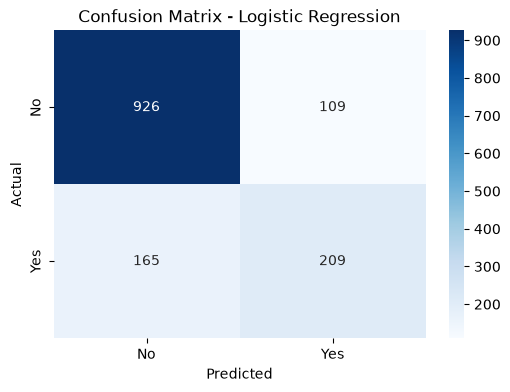

[[926 109]
 [165 209]]


In [55]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

print(cm)

In [56]:
from sklearn.metrics import roc_auc_score, roc_curve

In [57]:
y_prob = model.predict_proba(X_test_processed)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.8421


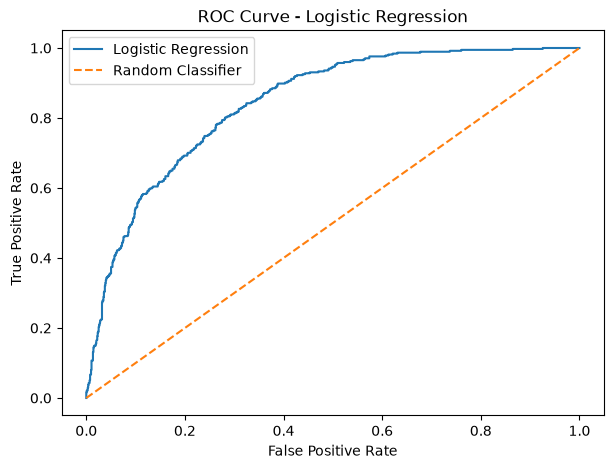

In [58]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob,
    pos_label="Yes"
)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")

plt.legend()
plt.show()

In [59]:
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve
)

In [60]:
pr_auc = average_precision_score(
    y_test,
    y_prob,
    pos_label="Yes"
)

print("PR-AUC Score:", round(pr_auc, 4))

PR-AUC Score: 0.6343


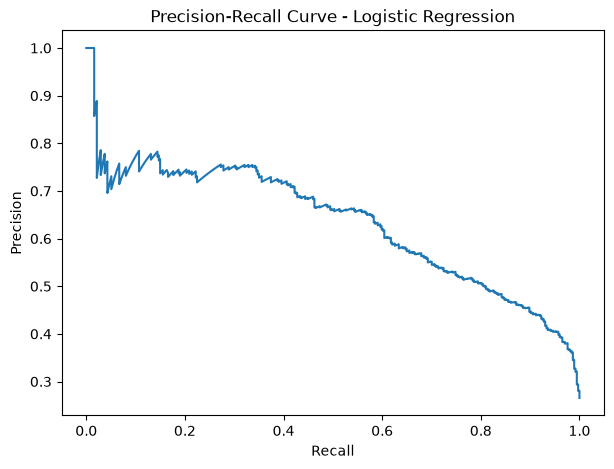

In [61]:
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob,
    pos_label="Yes"
)

plt.figure(figsize=(7, 5))

plt.plot(recall_values, precision_values)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")

plt.show()

In [62]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds_to_test = [0.3, 0.35, 0.4, 0.45, 0.5]

for threshold in thresholds_to_test:

    y_pred_threshold = np.where(
        y_prob >= threshold,
        "Yes",
        "No"
    )

    precision = precision_score(
        y_test,
        y_pred_threshold,
        pos_label="Yes"
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        pos_label="Yes"
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        pos_label="Yes"
    )

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))


Threshold: 0.3
Precision: 0.5193
Recall: 0.754
F1-score: 0.615

Threshold: 0.35
Precision: 0.5432
Recall: 0.7059
F1-score: 0.614

Threshold: 0.4
Precision: 0.5682
Recall: 0.6684
F1-score: 0.6143

Threshold: 0.45
Precision: 0.6021
Recall: 0.615
F1-score: 0.6085

Threshold: 0.5
Precision: 0.6572
Recall: 0.5588
F1-score: 0.604


In [63]:
#Metric	Default threshold (0.5)	Experimental threshold (0.3)
#Accuracy	80.55%	To calculate
#Precision	65.72%	51.93%
#Recall	55.88%	75.40%
#F1-score	60.40%	61.50%

In [64]:
from sklearn.tree import DecisionTreeClassifier

In [65]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    random_state=42
)

In [66]:
from sklearn.tree import DecisionTreeClassifier

In [67]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [68]:
y_pred_dt = dt_model.predict(X_test_processed)

print("First 10 predictions:")
print(y_pred_dt[:10])

print("\nActual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
['No' 'Yes' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No']

Actual values:
<StringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']
Length: 10, dtype: str


In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Decision Tree Evaluation")
print("------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_dt), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_dt, pos_label="Yes"), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_dt, pos_label="Yes"), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred_dt, pos_label="Yes"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Evaluation
------------------------
Accuracy: 0.7984
Precision: 0.6347
Recall: 0.5668
F1 Score: 0.5989

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.88      0.87      1035
         Yes       0.63      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [70]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Probability of a customer churning
yes_index = list(dt_model.classes_).index("Yes")
y_prob_dt = dt_model.predict_proba(X_test_processed)[:, yes_index]

# Evaluation
roc_auc_dt = roc_auc_score(
    (y_test == "Yes").astype(int), y_prob_dt
)

pr_auc_dt = average_precision_score(
    (y_test == "Yes").astype(int), y_prob_dt
)

print("ROC-AUC:", round(roc_auc_dt, 4))
print("PR-AUC:", round(pr_auc_dt, 4))


ROC-AUC: 0.8297
PR-AUC: 0.6218


In [71]:
train_accuracy_dt = dt_model.score(
    X_train_processed, y_train
)

test_accuracy_dt = dt_model.score(
    X_test_processed, y_test
)

print("Training Accuracy:", round(train_accuracy_dt, 4))
print("Testing Accuracy:", round(test_accuracy_dt, 4))

Training Accuracy: 0.8037
Testing Accuracy: 0.7984


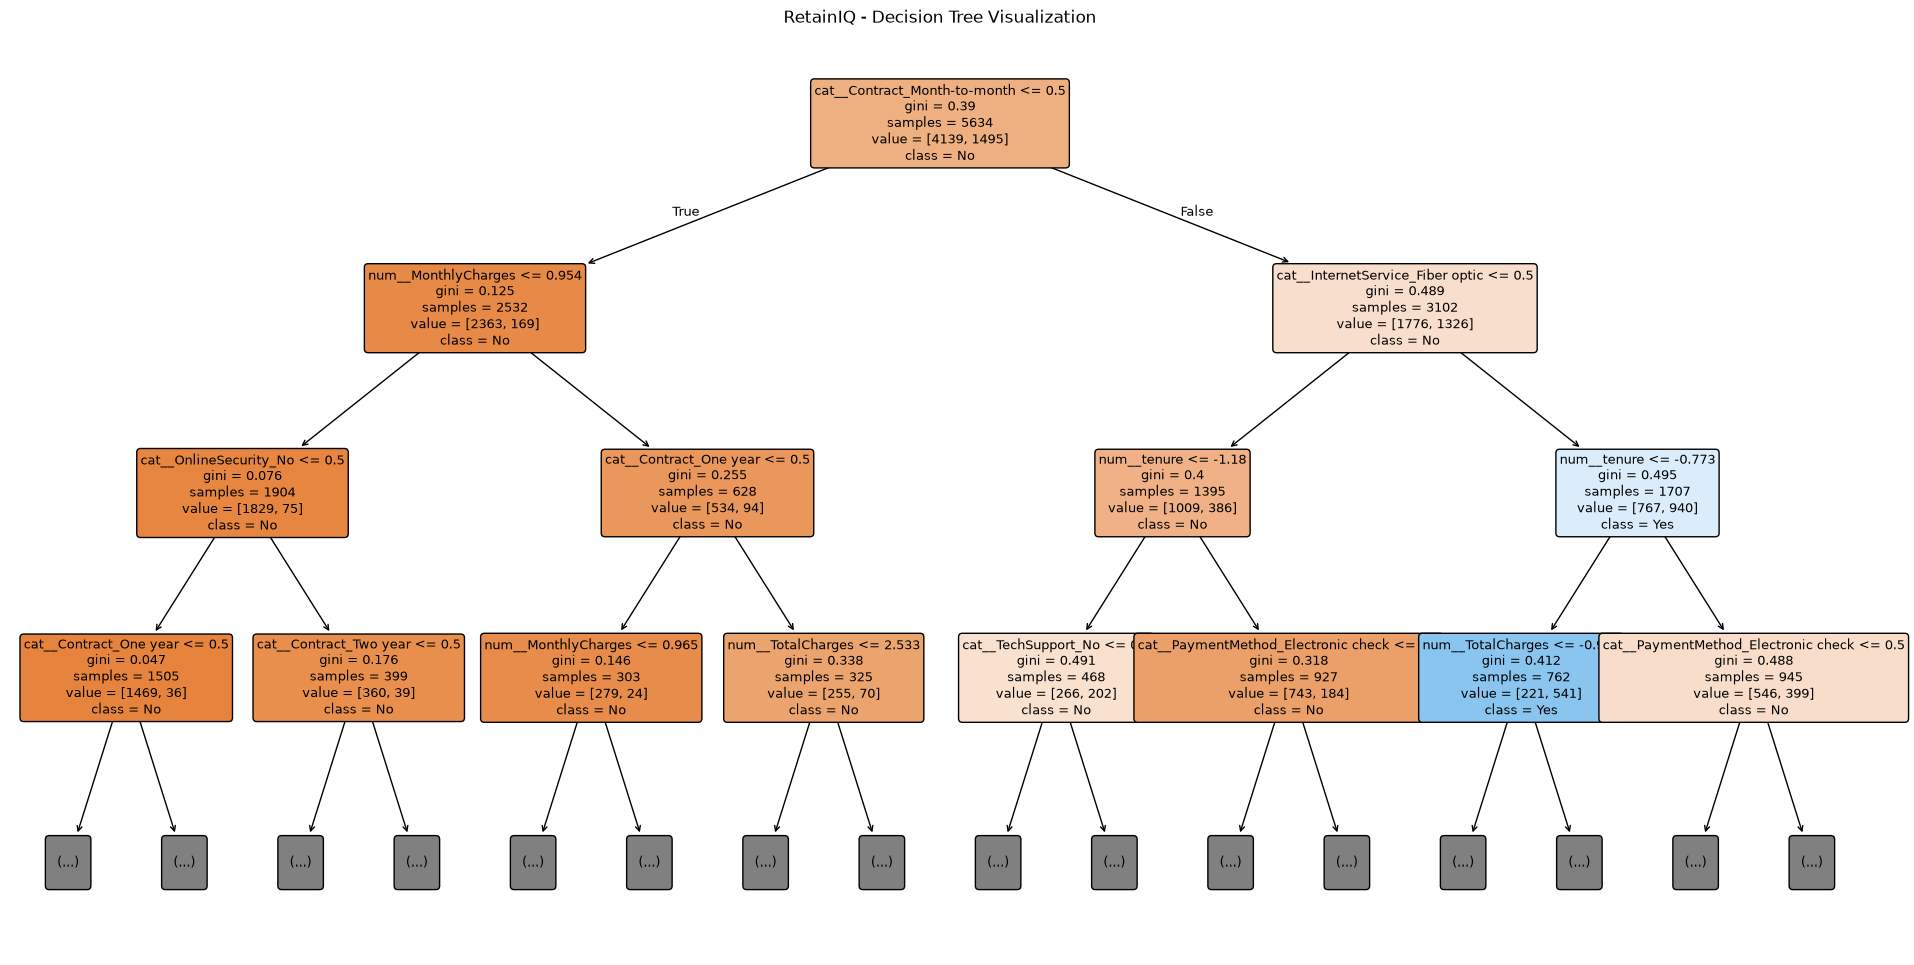

In [72]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(
    dt_model,
    max_depth=3,
    filled=True,
    feature_names=preprocessor.get_feature_names_out(),
    class_names=["No", "Yes"],
    rounded=True,
    fontsize=9
)

plt.title("RetainIQ - Decision Tree Visualization")
plt.show()

In [73]:
#Model	Accuracy	F1	ROC-AUC
#Logistic Regression	80.55%	60.40%	0.8421
#Decision Tree	79.84%	59.89%	0.8297

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                                Feature  Importance
36         cat__Contract_Month-to-month    0.515311
16     cat__InternetService_Fiber optic    0.163687
1                           num__tenure    0.157125
2                   num__MonthlyCharges    0.036015
3                     num__TotalCharges    0.035884
43  cat__PaymentMethod_Electronic check    0.028004
27                  cat__TechSupport_No    0.021433
37               cat__Contract_One year    0.009242
21                 cat__OnlineBackup_No    0.009222
18               cat__OnlineSecurity_No    0.008642
29                 cat__TechSupport_Yes    0.005461
0                    num__SeniorCitizen    0.004923
38               cat__Contract_Two year    0.002549
44      cat__PaymentMethod_Mailed check    0.002501
12                cat__MultipleLines_No    0.000000


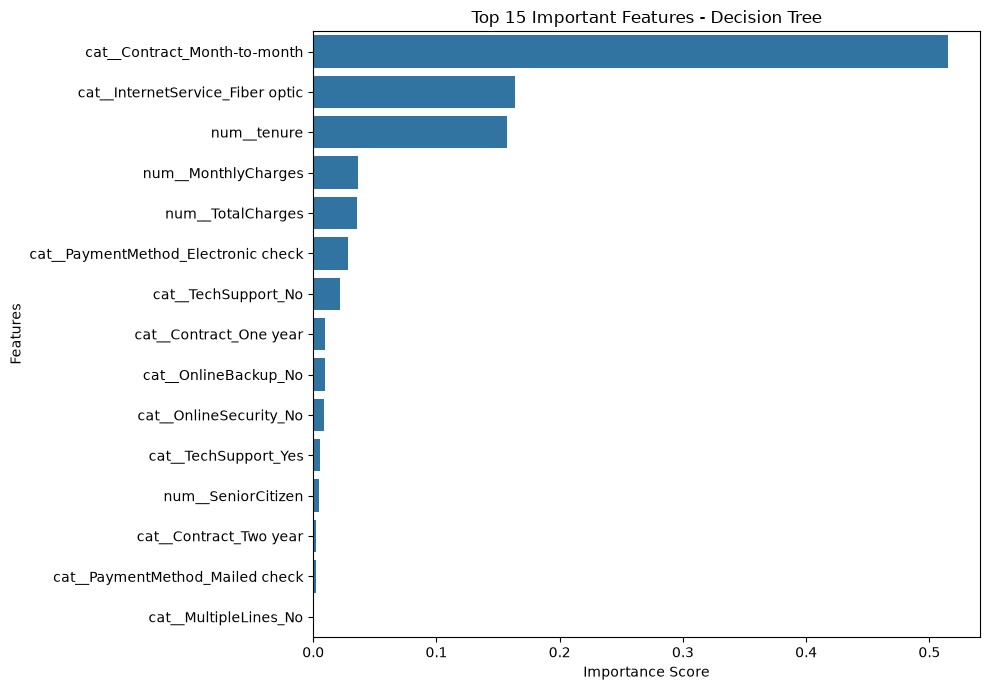

In [75]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Decision Tree")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [76]:
from sklearn.ensemble import RandomForestClassifier

In [77]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

In [78]:
rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [79]:
rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [80]:
y_pred_rf = rf_model.predict(X_test_processed)

print("First 10 predictions:")
print(y_pred_rf[:10])

print("\nActual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']

Actual values:
<StringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']
Length: 10, dtype: str


In [81]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Random Forest Evaluation")
print("------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_rf, pos_label="Yes"), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_rf, pos_label="Yes"), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred_rf, pos_label="Yes"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Evaluation
------------------------
Accuracy: 0.8013
Precision: 0.6655
Recall: 0.5053
F1 Score: 0.5745

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.91      0.87      1035
         Yes       0.67      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [82]:
from sklearn.metrics import roc_auc_score, average_precision_score

yes_index = list(rf_model.classes_).index("Yes")

y_prob_rf = rf_model.predict_proba(
    X_test_processed
)[:, yes_index]

roc_auc_rf = roc_auc_score(
    (y_test == "Yes").astype(int),
    y_prob_rf
)

pr_auc_rf = average_precision_score(
    (y_test == "Yes").astype(int),
    y_prob_rf
)

print("ROC-AUC:", round(roc_auc_rf, 4))
print("PR-AUC:", round(pr_auc_rf, 4))

ROC-AUC: 0.8385
PR-AUC: 0.6508


In [83]:
from sklearn.ensemble import GradientBoostingClassifier

In [84]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

In [85]:
from scipy.sparse import issparse

print("Training data is sparse:", issparse(X_train_processed))

Training data is sparse: False


In [86]:
if issparse(X_train_processed):
    X_train_gb = X_train_processed.toarray()
    X_test_gb = X_test_processed.toarray()
else:
    X_train_gb = X_train_processed
    X_test_gb = X_test_processed

gb_model.fit(X_train_gb, y_train)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [87]:
y_pred_gb = gb_model.predict(X_test_gb)

print("First 10 predictions:")
print(y_pred_gb[:10])

print("\nActual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']

Actual values:
<StringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']
Length: 10, dtype: str


In [88]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Gradient Boosting Evaluation")
print("----------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_gb), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_gb, pos_label="Yes"), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_gb, pos_label="Yes"), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred_gb, pos_label="Yes"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Evaluation
----------------------------
Accuracy: 0.8027
Precision: 0.6655
Recall: 0.516
F1 Score: 0.5813

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.91      0.87      1035
         Yes       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [89]:
from sklearn.metrics import roc_auc_score, average_precision_score

yes_index = list(gb_model.classes_).index("Yes")

y_prob_gb = gb_model.predict_proba(X_test_gb)[:, yes_index]

roc_auc_gb = roc_auc_score(
    (y_test == "Yes").astype(int),
    y_prob_gb
)

pr_auc_gb = average_precision_score(
    (y_test == "Yes").astype(int),
    y_prob_gb
)

print("ROC-AUC:", round(roc_auc_gb, 4))
print("PR-AUC:", round(pr_auc_gb, 4))

ROC-AUC: 0.8433
PR-AUC: 0.66


In [90]:
#Metric	Logistic Regression	Decision Tree	Random Forest	Gradient Boosting
#Accuracy	80.55%	79.84%	80.13%	80.27%
#Precision	65.72%	63.47%	66.55%	66.55%
#Recall	55.88%	56.68%	50.53%	51.60%
#F1 Score	60.40%	59.89%	57.45%	58.13%
#ROC-AUC	0.8421	0.8297	0.8385	0.8433
#PR-AUC	0.6343	0.6218	0.6508	0.6600

In [91]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [0.8055, 0.7984, 0.8013, 0.8027],
    "Precision": [0.6572, 0.6347, 0.6655, 0.6655],
    "Recall": [0.5588, 0.5668, 0.5053, 0.5160],
    "F1 Score": [0.6040, 0.5989, 0.5745, 0.5813],
    "ROC-AUC": [0.8421, 0.8297, 0.8385, 0.8433],
    "PR-AUC": [0.6343, 0.6218, 0.6508, 0.6600]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421,0.6343
1,Decision Tree,0.7984,0.6347,0.5668,0.5989,0.8297,0.6218
2,Random Forest,0.8013,0.6655,0.5053,0.5745,0.8385,0.6508
3,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8433,0.6600


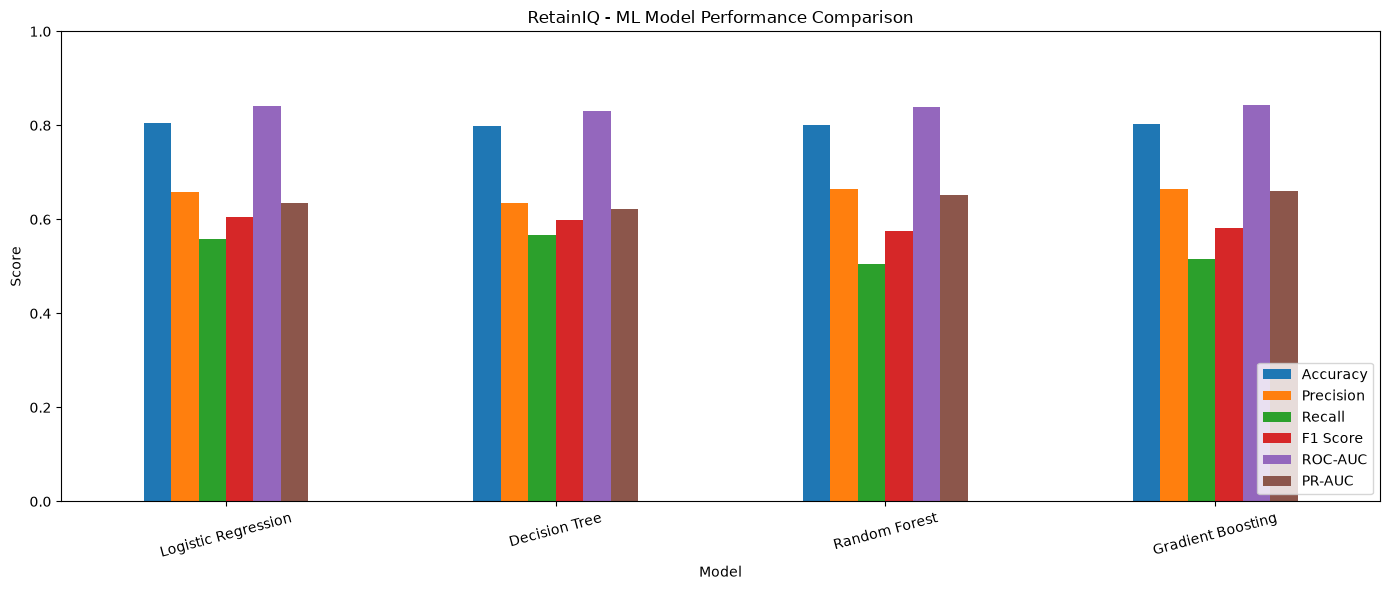

In [92]:
model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]
].plot(kind="bar", figsize=(14, 6))

plt.title("RetainIQ - ML Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [93]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train_new.shape)
print("Validation data:", X_val.shape)

Training data: (4507, 19)
Validation data: (1127, 19)


In [94]:
X_train_new_processed = preprocessor.fit_transform(X_train_new)

X_val_processed = preprocessor.transform(X_val)

In [95]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [96]:
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

In [97]:
param_grid_lr = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"]
}

In [98]:
grid_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

In [99]:
grid_lr.fit(X_train_new, y_train_new)

print("Best Parameters:", grid_lr.best_params_)
print("Best Cross-validation F1:", round(grid_lr.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__C': 0.01, 'classifier__solver': 'liblinear'}
Best Cross-validation F1: nan


C:\Navya\RetainIQ\venv\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


In [100]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [101]:
from sklearn.metrics import make_scorer, f1_score

churn_f1 = make_scorer(
    f1_score,
    pos_label="Yes"
)

In [102]:
grid_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    cv=5,
    scoring=churn_f1,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

In [103]:
grid_lr.fit(X_train_new, y_train_new)

print("Best Parameters:", grid_lr.best_params_)
print("Best Cross-validation F1:", round(grid_lr.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__C': 100, 'classifier__solver': 'lbfgs'}
Best Cross-validation F1: 0.5963


In [104]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

best_lr_model = grid_lr.best_estimator_

y_val_pred_lr = best_lr_model.predict(X_val)
y_val_prob_lr = best_lr_model.predict_proba(X_val)[:, 
    list(best_lr_model.classes_).index("Yes")
]

print("Tuned Logistic Regression Results")
print("---------------------------------")
print("Accuracy:", accuracy_score(y_val, y_val_pred_lr))
print("Precision:", precision_score(y_val, y_val_pred_lr, pos_label="Yes"))
print("Recall:", recall_score(y_val, y_val_pred_lr, pos_label="Yes"))
print("F1 Score:", f1_score(y_val, y_val_pred_lr, pos_label="Yes"))
print("ROC-AUC:", roc_auc_score(y_val == "Yes", y_val_prob_lr))
print("PR-AUC:", average_precision_score(y_val == "Yes", y_val_prob_lr))

Tuned Logistic Regression Results
---------------------------------
Accuracy: 0.8172138420585625
Precision: 0.6962025316455697
Recall: 0.5518394648829431
F1 Score: 0.6156716417910447
ROC-AUC: 0.8486096973809639
PR-AUC: 0.6643812368181241


In [105]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

In [106]:
param_grid_dt = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10]
}

In [107]:
grid_dt = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid_dt,
    cv=5,
    scoring=churn_f1,
    n_jobs=-1,
    verbose=1
)

grid_dt.fit(X_train_new, y_train_new)

print("Best Parameters:", grid_dt.best_params_)
print("Best Cross-validation F1:", round(grid_dt.best_score_, 4))

Fitting 5 folds for each of 45 candidates, totalling 225 fits
Best Parameters: {'classifier__max_depth': 7, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 20}
Best Cross-validation F1: 0.5573


In [108]:
best_dt_model = grid_dt.best_estimator_

y_val_pred_dt = best_dt_model.predict(X_val)

y_val_prob_dt = best_dt_model.predict_proba(X_val)[:, 
    list(best_dt_model.classes_).index("Yes")
]

In [109]:
print("Tuned Decision Tree Results")
print("---------------------------------")
print("Accuracy:", accuracy_score(y_val, y_val_pred_dt))
print("Precision:", precision_score(y_val, y_val_pred_dt, pos_label="Yes"))
print("Recall:", recall_score(y_val, y_val_pred_dt, pos_label="Yes"))
print("F1 Score:", f1_score(y_val, y_val_pred_dt, pos_label="Yes"))
print("ROC-AUC:", roc_auc_score(y_val == "Yes", y_val_prob_dt))
print("PR-AUC:", average_precision_score(y_val == "Yes", y_val_prob_dt))

Tuned Decision Tree Results
---------------------------------
Accuracy: 0.7888198757763976
Precision: 0.6177606177606177
Recall: 0.5351170568561873
F1 Score: 0.5734767025089605
ROC-AUC: 0.8093605092659913
PR-AUC: 0.5921677866118638


In [110]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

In [111]:
param_grid_rf = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 2, 5]
}

In [112]:
grid_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    cv=5,
    scoring=churn_f1,
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train_new, y_train_new)

print("Best Parameters:", grid_rf.best_params_)
print("Best Cross-validation F1:", round(grid_rf.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best Cross-validation F1: 0.5775


In [113]:
best_rf_model = grid_rf.best_estimator_

y_val_pred_rf = best_rf_model.predict(X_val)

y_val_prob_rf = best_rf_model.predict_proba(X_val)[:, 
    list(best_rf_model.classes_).index("Yes")
]

In [114]:
print("Tuned Random Forest Results")
print("---------------------------------")
print("Accuracy:", accuracy_score(y_val, y_val_pred_rf))
print("Precision:", precision_score(y_val, y_val_pred_rf, pos_label="Yes"))
print("Recall:", recall_score(y_val, y_val_pred_rf, pos_label="Yes"))
print("F1 Score:", f1_score(y_val, y_val_pred_rf, pos_label="Yes"))
print("ROC-AUC:", roc_auc_score(y_val == "Yes", y_val_prob_rf))
print("PR-AUC:", average_precision_score(y_val == "Yes", y_val_prob_rf))

Tuned Random Forest Results
---------------------------------
Accuracy: 0.8074534161490683
Precision: 0.6846846846846847
Recall: 0.5083612040133779
F1 Score: 0.5834932821497121
ROC-AUC: 0.8456368248428742
PR-AUC: 0.6558862436004964


In [115]:
#Model	F1 Score	ROC-AUC	PR-AUC
#Logistic Regression	61.57%	0.8486	0.6644
#Decision Tree	57.35%	0.8094	0.5922
#Random Forest	58.35%	0.8456	0.6559

In [116]:
preprocessor_dense = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=0
)

In [117]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor_dense),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

In [118]:
param_grid_gb = {
    "classifier__n_estimators": [100, 150],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [2, 3],
    "classifier__min_samples_leaf": [1, 5]
}

In [119]:
grid_gb = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid_gb,
    cv=5,
    scoring=churn_f1,
    n_jobs=-1,
    verbose=1
)

grid_gb.fit(X_train_new, y_train_new)

print("Best Parameters:", grid_gb.best_params_)
print("Best Cross-validation F1:", round(grid_gb.best_score_, 4))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 150}
Best Cross-validation F1: 0.5861


In [120]:
best_gb_model = grid_gb.best_estimator_

y_val_pred_gb = best_gb_model.predict(X_val)

y_val_prob_gb = best_gb_model.predict_proba(X_val)[:, 
    list(best_gb_model.classes_).index("Yes")
]


In [121]:
print("Tuned Gradient Boosting Results")
print("---------------------------------")
print("Accuracy:", accuracy_score(y_val, y_val_pred_gb))
print("Precision:", precision_score(y_val, y_val_pred_gb, pos_label="Yes"))
print("Recall:", recall_score(y_val, y_val_pred_gb, pos_label="Yes"))
print("F1 Score:", f1_score(y_val, y_val_pred_gb, pos_label="Yes"))
print("ROC-AUC:", roc_auc_score(y_val == "Yes", y_val_prob_gb))
print("PR-AUC:", average_precision_score(y_val == "Yes", y_val_prob_gb))

Tuned Gradient Boosting Results
---------------------------------
Accuracy: 0.8101153504880213
Precision: 0.7014218009478673
Recall: 0.49498327759197325
F1 Score: 0.5803921568627451
ROC-AUC: 0.8514856284232467
PR-AUC: 0.671431923978057


In [122]:
#Metric	Logistic Regression	Decision Tree	Random Forest	Gradient Boosting
#Accuracy	81.72%	78.88%	80.75%	81.01%
#Precision	69.62%	61.78%	68.47%	70.14%
#Recall	55.18%	53.51%	50.84%	49.50%
#F1	61.57%	57.35%	58.35%	58.04%
#ROC-AUC	0.8486	0.8094	0.8456	0.8515
#PR-AUC	0.6644	0.5922	0.6559	0.6714

In [123]:
#Current model leaders
#Best F1 score
#Logistic Regression

#Best ROC-AUC
#Gradient Boosting

#Best PR-AUC
#Gradient Boosting

#Best precision
#Gradient Boosting

In [124]:
model_comparison_tuned = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_val_pred_lr),
        accuracy_score(y_val, y_val_pred_dt),
        accuracy_score(y_val, y_val_pred_rf),
        accuracy_score(y_val, y_val_pred_gb)
    ],
    "Precision": [
        precision_score(y_val, y_val_pred_lr, pos_label="Yes"),
        precision_score(y_val, y_val_pred_dt, pos_label="Yes"),
        precision_score(y_val, y_val_pred_rf, pos_label="Yes"),
        precision_score(y_val, y_val_pred_gb, pos_label="Yes")
    ],
    "Recall": [
        recall_score(y_val, y_val_pred_lr, pos_label="Yes"),
        recall_score(y_val, y_val_pred_dt, pos_label="Yes"),
        recall_score(y_val, y_val_pred_rf, pos_label="Yes"),
        recall_score(y_val, y_val_pred_gb, pos_label="Yes")
    ],
    "F1 Score": [
        f1_score(y_val, y_val_pred_lr, pos_label="Yes"),
        f1_score(y_val, y_val_pred_dt, pos_label="Yes"),
        f1_score(y_val, y_val_pred_rf, pos_label="Yes"),
        f1_score(y_val, y_val_pred_gb, pos_label="Yes")
    ],
    "ROC-AUC": [
        roc_auc_score(y_val == "Yes", y_val_prob_lr),
        roc_auc_score(y_val == "Yes", y_val_prob_dt),
        roc_auc_score(y_val == "Yes", y_val_prob_rf),
        roc_auc_score(y_val == "Yes", y_val_prob_gb)
    ],
    "PR-AUC": [
        average_precision_score(y_val == "Yes", y_val_prob_lr),
        average_precision_score(y_val == "Yes", y_val_prob_dt),
        average_precision_score(y_val == "Yes", y_val_prob_rf),
        average_precision_score(y_val == "Yes", y_val_prob_gb)
    ]
})

model_comparison_tuned.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8172,0.6962,0.5518,0.6157,0.8486,0.6644
1,Decision Tree,0.7888,0.6178,0.5351,0.5735,0.8094,0.5922
2,Random Forest,0.8075,0.6847,0.5084,0.5835,0.8456,0.6559
3,Gradient Boosting,0.8101,0.7014,0.4950,0.5804,0.8515,0.6714


In [125]:
best_gb_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returnd

In [126]:
import joblib

joblib.dump(
    best_gb_model,
    "../models/best_gradient_boosting.pkl"
)

print("Model saved successfully!")

Model saved successfully!
